# HTR baseline A: validation results

Evaluates `models/trocr-uk-baseline` (trained in `02_htr_baseline_train.ipynb`) on the validation split's
ground-truth line crops: CER/WER overall, per source, and per annotation source, with page-bootstrap 95%
intervals, then error examples. Other crops (for example detector output) can be evaluated by loading a table
with the same columns as `crops.csv`; `crop_path` may be absolute.

In [1]:
import json
import sys
import time
from collections import Counter
from pathlib import Path

import jiwer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from transformers.utils import logging

sys.path.insert(0, '../src')
from htr import CROP_DIR, CROP_FILE, cer, predict, wer

logging.set_verbosity_error()
logging.disable_progress_bar()
pd.set_option('display.max_colwidth', 120)

MODEL_DIR = Path('../models/trocr-uk-baseline')
RESULTS_DIR = Path('../results/htr')
DECODING = dict(num_beams=4, no_repeat_ngram_size=0, max_length=130)
SEED = 42

/home/stalex/unik_shit/ai/pandemonium-rukopys/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
processor = TrOCRProcessor.from_pretrained(MODEL_DIR)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_DIR).cuda()
val = pd.read_csv(CROP_FILE).query("split == 'val'").dropna(subset=['target']).copy()
start = time.time()
val['prediction'] = predict(model, processor, val, **DECODING)
ms_per_line = 1000 * (time.time() - start) / len(val)
measures = [jiwer.process_characters(r, h) for r, h in zip(val.target, val.prediction)]
val['char_errors'] = [m.substitutions + m.deletions + m.insertions for m in measures]
val['chars'] = val.target.str.len()
val['line_CER'] = val.char_errors / val.chars


def page_bootstrap(group, n=1000):
    pages = group.groupby('page_id')[['char_errors', 'chars']].sum().to_numpy()
    idx = np.random.default_rng(SEED).integers(0, len(pages), (n, len(pages)))
    sample = pages[idx].sum(axis=1)
    return np.percentile(sample[:, 0] / sample[:, 1], [2.5, 97.5])


def summary(group):
    low, high = page_bootstrap(group)
    return pd.Series(dict(pages=group.page_id.nunique(), lines=len(group), CER=cer(group.target, group.prediction),
                          CER_95_low=low, CER_95_high=high, WER=wer(group.target, group.prediction)))


by_source = val.groupby('source').apply(summary, include_groups=False)
metrics = pd.concat([by_source, summary(val).to_frame('all').T])
print(f'{len(val)} lines, beam 4, {ms_per_line:.0f} ms per line')
metrics.round(4)

2076 lines, beam 4, 122 ms per line


,pages,lines,CER,CER_95_low,CER_95_high,WER
archive,13.0,305.0,0.1177,0.0912,0.1443,0.3562
dictation,36.0,802.0,0.0784,0.0303,0.1672,0.1774
school,67.0,691.0,0.1191,0.0892,0.1523,0.3746
university,15.0,278.0,0.1951,0.1430,0.2522,0.5537
all,131.0,2076.0,0.1145,0.0833,0.1571,0.3150


In [3]:
val.groupby('annotation_source').apply(summary, include_groups=False).round(4)

,pages,lines,CER,CER_95_low,CER_95_high,WER
annotation_source,,,,,,
annotator,85.0,1488.0,0.1007,0.0767,0.1320,0.3023
volunteer,46.0,588.0,0.1529,0.0699,0.2796,0.3490


Error rate by line length. TrOCR squeezes every crop into 384×384, so long lines lose horizontal resolution.

In [4]:
val['length'] = pd.cut(val.chars, [0, 20, 40, 60, 1000], labels=['≤20', '21–40', '41–60', '>60'])
val.groupby('length', observed=True).apply(
    lambda g: pd.Series(dict(lines=len(g), CER=cer(g.target, g.prediction))), include_groups=False).round(4)

,lines,CER
length,,
≤20,522.0,0.1192
21–40,959.0,0.0729
41–60,487.0,0.1420
>60,108.0,0.2003


## Errors

Most frequent character substitutions (reference → prediction):

In [5]:
confusions = Counter()
for (r, h), m in zip(zip(val.target, val.prediction), measures):
    for chunk in m.alignments[0]:
        if chunk.type == 'substitute':
            confusions.update(zip(r[chunk.ref_start_idx:chunk.ref_end_idx], h[chunk.hyp_start_idx:chunk.hyp_end_idx]))
pd.DataFrame([(f'{a} → {b}', n) for (a, b), n in confusions.most_common(15)], columns=['substitution', 'count'])

,substitution,count
0,а → о,127
1,о → а,117
2,к → н,65
3,а → и,61
4,е → а,48
5,н → к,41
6,е → о,41
7,і → о,39
8,м → н,39
9,л → м,38


Worst lines (at least 15 characters), two per source:

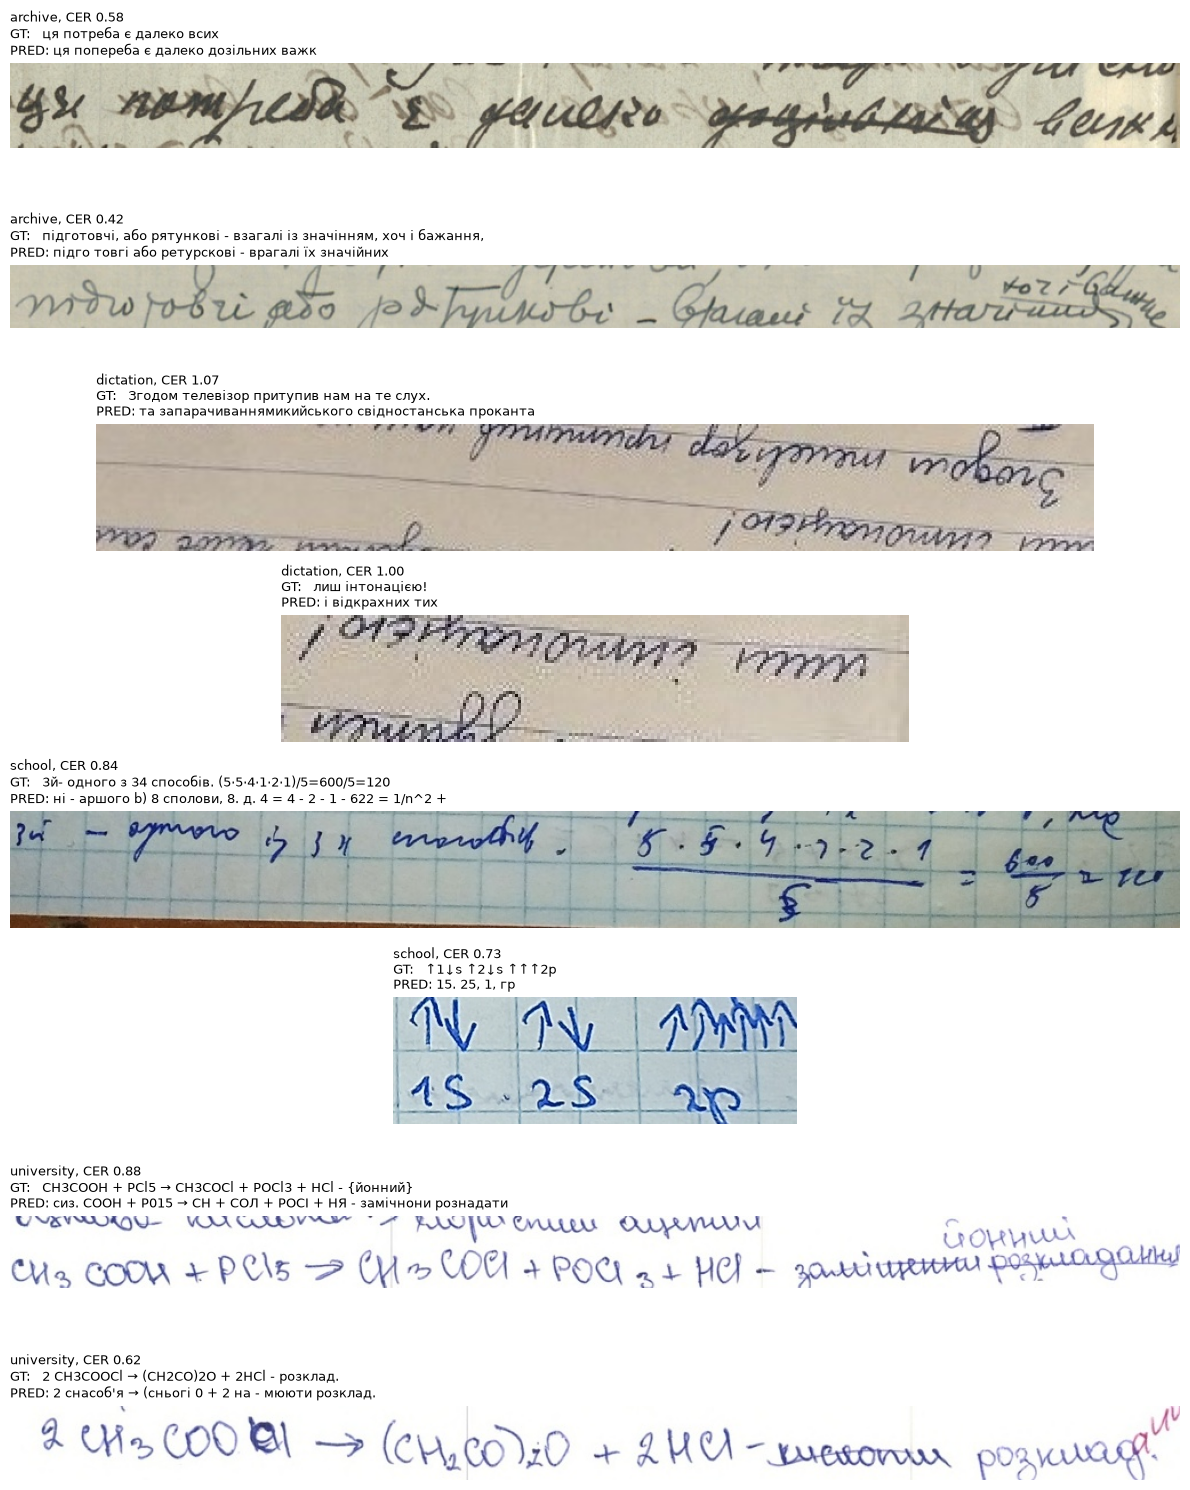

In [6]:
worst = (val[val.chars >= 15].sort_values('line_CER', ascending=False)
         .groupby('source', group_keys=False).head(2).sort_values('source'))
fig, axes = plt.subplots(len(worst), 1, figsize=(12, 1.9 * len(worst)))
for ax, row in zip(axes, worst.itertuples()):
    with Image.open(CROP_DIR / row.crop_path) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f'{row.source}, CER {row.line_CER:.2f}\nGT:   {row.target}\nPRED: {row.prediction}',
                 loc='left', fontsize=9)
    ax.axis('off')
fig.tight_layout()

Typical lines (random, two per source) to show what the median case looks like:

In [7]:
val.groupby('source', group_keys=False).sample(2, random_state=SEED)[['source', 'line_CER', 'target', 'prediction']].round(3)

,source,line_CER,target,prediction
10130,archive,0.074,вічне Завтра - фата-моргана,вічне Завтра - фата-морічна
9705,archive,0.094,них генералів прийти на допомогу,них генералів прийти на допологу я
7683,dictation,0.891,"Всеукраїнський диктант єдності ""Магія голосу"".",„Катт упери школогіва межентів стантавівся
1333,dictation,0.000,а до легендарної співачки,а до легендарної співачки
20509,school,0.000,Домашня робота,Домашня робота
17299,school,0.000,Домашня робота,Домашня робота
12332,university,0.036,T - обсяг вироблених товарів,Т - обсяг вироблених товарів
11974,university,0.000,Завдання 2,Завдання 2


## Save results

Model weights stay out of Git (`models/`). Predictions and metrics in `results/htr/` are small and can be committed.

In [8]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
columns = ['page_id', 'region', 'crop_path', 'source', 'annotation_source', 'target', 'prediction', 'char_errors', 'chars']
val[columns].to_csv(RESULTS_DIR / 'val_predictions.csv', index=False)
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(dict(
    model=str(MODEL_DIR), decoding=DECODING, ms_per_line=ms_per_line,
    validation=metrics.reset_index(names='group').to_dict('records'),
), indent=2), encoding='utf-8')

1353